# The Guiding Center Approximation for Low-Eccentricity Orbits

Most planets and moons move on ellipses with small eccentricities. For those orbits, Keplerian motion can be approximated by nested circular and elliptical motions, a modern cousin of the ancient theory of epicycles. One elegant version is the **guiding center approximation**:

1. A point $G$, the *guiding center*, moves uniformly on a circle of radius $a$ centered on the focus, with the mean motion $n$:
$$x_G = a\cos M,\quad y_G = a\sin M,\quad M = nt$$
2. The body moves on a small ellipse around $G$, described in a frame $(x', y')$ that **rotates** with $G$:
$$x' = -ae\cos M,\quad y' = 2ae\sin M$$

The exact Keplerian orbit is $x = r\cos f$, $y = r\sin f$ with $r = a(1-e\cos E)$ and Kepler's equation $E - e\sin E = M$.

In this notebook I test how good the approximation is, and show why its error scales as $e^2$.

## Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. The exact orbit

Kepler's equation has no closed-form solution, so I solve it with Newton's method, vectorized over all times at once:

$$E_{k+1} = E_k - \frac{E_k - e\sin E_k - M}{1 - e\cos E_k}$$

In [2]:
def solve_kepler(M, e, tol=1e-12):
  # For small eccentricities E is close to M: good starting guess
  E = M.copy()
  for i in range(50):
    dE = (E - e*np.sin(E) - M) / (1 - e*np.cos(E))
    E = E - dE
    if np.max(np.abs(dE)) < tol:
      break
  return E

From $E$ I get $r$ and the true anomaly $f$, using $\tan\frac{f}{2} = \sqrt{\frac{1+e}{1-e}}\tan\frac{E}{2}$ with `arctan2` to avoid quadrant issues:

In [3]:
def exact_orbit(a, e, M):
  E = solve_kepler(M, e)
  r = a*(1 - e*np.cos(E))
  f = 2*np.arctan2(np.sqrt(1 + e)*np.sin(E/2),
                   np.sqrt(1 - e)*np.cos(E/2))
  return r*np.cos(f), r*np.sin(f)

## 2. The guiding center approximation

The key detail is that $(x', y')$ lives in a **rotating** frame: $x'$ points radially (from the focus toward $G$) and $y'$ along the direction of motion. Its unit vectors, written in the fixed frame, are

$$\hat{x}' = (\cos M, \sin M),\qquad \hat{y}' = (-\sin M, \cos M)$$

so the body's position in the fixed frame is

$$\vec{r} = \vec{r}_G + x'\,\hat{x}' + y'\,\hat{y}'$$

In [4]:
def guiding_center(a, e, M):
  # Guiding center G (fixed frame centered on the focus)
  xG = a*np.cos(M)
  yG = a*np.sin(M)

  # Body relative to G in the rotating frame
  xp = -a*e*np.cos(M)
  yp = 2*a*e*np.sin(M)

  # Rotate to the fixed frame and add G
  x = xG + xp*np.cos(M) - yp*np.sin(M)
  y = yG + xp*np.sin(M) + yp*np.cos(M)
  return x, y, xG, yG

## 3. Comparing the orbits

I use $a = 1$ and a small eccentricity $e = 0.1$, over one full orbit ($M$ from 0 to $2\pi$). Besides both orbits and the guide circle, I draw the small ellipse around $G$ at a few instants. To draw it at a given $M_0$, the rotating axes are frozen at $M_0$ and the full ellipse $(-ae\cos\phi,\ 2ae\sin\phi)$ is traced.

In [5]:
a = 1.0
e = 0.1
M = np.linspace(0, 2*np.pi, 500)

x_ex, y_ex = exact_orbit(a, e, M)
x_gc, y_gc, xG, yG = guiding_center(a, e, M)

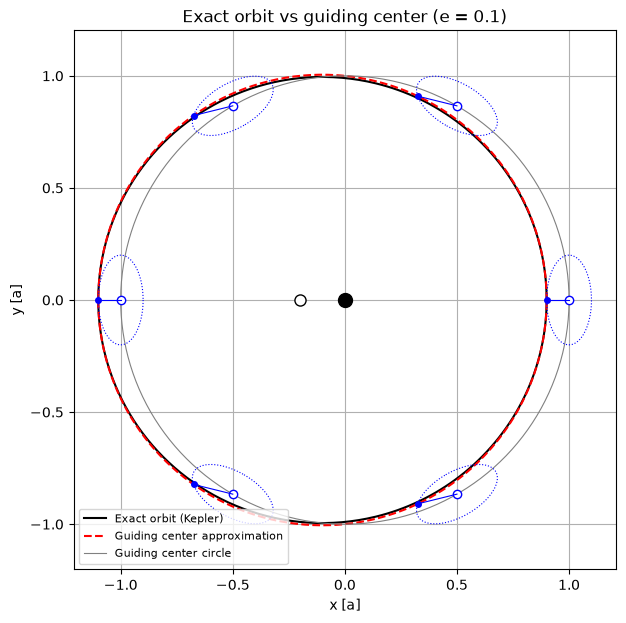

In [6]:
plt.figure(figsize=(7, 7))
plt.plot(x_ex, y_ex, 'k-', label='Exact orbit (Kepler)')
plt.plot(x_gc, y_gc, 'r--', label='Guiding center approximation')
plt.plot(xG, yG, color='gray', lw=0.8, label='Guiding center circle')

# Focus (Sun) and empty focus at x = -2ae
plt.plot(0, 0, 'ko', ms=10)
plt.plot(-2*a*e, 0, 'o', mfc='white', mec='k', ms=8)

# Epicycles around G at a few instants
phi = np.linspace(0, 2*np.pi, 100)
for M0 in np.radians([0, 60, 120, 180, 240, 300]):
  xp = -a*e*np.cos(phi)
  yp = 2*a*e*np.sin(phi)
  xe = a*np.cos(M0) + xp*np.cos(M0) - yp*np.sin(M0)
  ye = a*np.sin(M0) + xp*np.sin(M0) + yp*np.cos(M0)
  plt.plot(xe, ye, 'b:', lw=0.8)
  x1, y1, xg1, yg1 = guiding_center(a, e, np.array([M0]))
  plt.plot(xg1, yg1, 'o', mfc='white', mec='b')
  plt.plot(x1, y1, 'bo', ms=4)
  plt.plot([xg1[0], x1[0]], [yg1[0], y1[0]], 'b-', lw=0.8)

plt.title(f'Exact orbit vs guiding center (e = {e})')
plt.xlabel('x [a]')
plt.ylabel('y [a]')
plt.axis('equal')
plt.legend(loc='lower left', fontsize=8)
plt.grid()
plt.savefig('guiding_center_orbit.png', dpi=110)
plt.show()

Both orbits almost overlap. The guide circle is shifted with respect to the ellipse: at pericenter ($M = 0$) the body is **closer** to the focus than $G$, since $x' = -ae$, and at apocenter it is farther away.

The small ellipse around $G$ has its along-track semi-axis ($2ae$) **twice** the radial one ($ae$), and it is traversed in the opposite direction to the orbital motion.

## 4. Motion in time

The approximation should reproduce not only the shape of the orbit but also **where** the body is at each moment. Comparing positions at six instants:

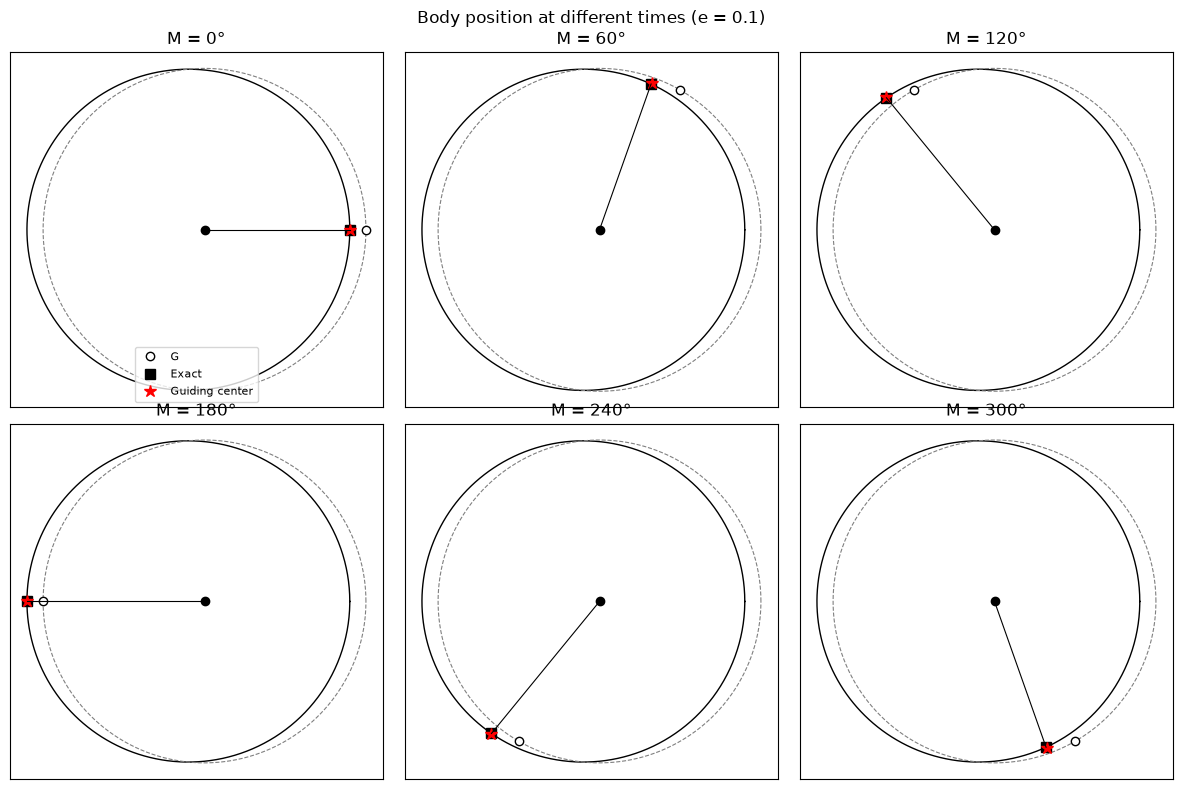

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
instants = np.radians([0, 60, 120, 180, 240, 300])

for ax, M0 in zip(axes.flatten(), instants):
  ax.plot(x_ex, y_ex, 'k-', lw=1)
  ax.plot(xG, yG, color='gray', ls='--', lw=0.8)
  ax.plot(0, 0, 'ko')

  xe0, ye0 = exact_orbit(a, e, np.array([M0]))
  xc0, yc0, xg0, yg0 = guiding_center(a, e, np.array([M0]))
  ax.plot(xg0, yg0, 'o', mfc='white', mec='k', label='G')
  ax.plot(xe0, ye0, 'ks', ms=7, label='Exact')
  ax.plot(xc0, yc0, 'r*', ms=9, label='Guiding center')
  ax.plot([0, xe0[0]], [0, ye0[0]], 'k-', lw=0.8)

  ax.set_title(f'M = {np.degrees(M0):.0f}°')
  ax.set_aspect('equal')
  ax.set_xticks([])
  ax.set_yticks([])

axes[0, 0].legend(fontsize=8, loc='lower center')
plt.suptitle(f'Body position at different times (e = {e})')
plt.tight_layout()
plt.show()

At every instant the red star (approximation) lands practically on top of the black square (exact position).

## 5. How good is the approximation?

The distance between the exact and approximate positions along the orbit, in units of $a$:

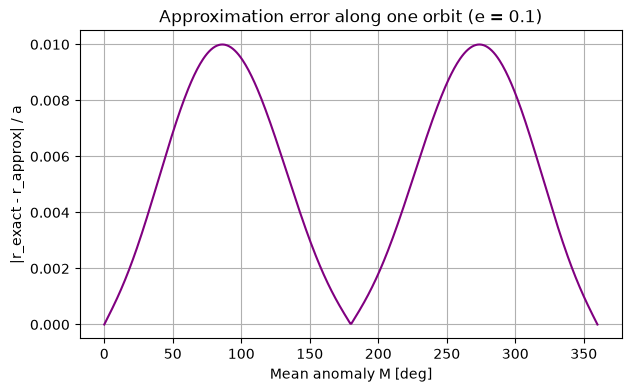

Maximum error: 0.00999 a
Compared with e^2 = 0.01000


In [8]:
error = np.sqrt((x_ex - x_gc)**2 + (y_ex - y_gc)**2) / a

plt.figure(figsize=(7, 4))
plt.plot(np.degrees(M), error, color='purple')
plt.title(f'Approximation error along one orbit (e = {e})')
plt.xlabel('Mean anomaly M [deg]')
plt.ylabel('|r_exact - r_approx| / a')
plt.grid()
plt.show()

print(f"Maximum error: {error.max():.5f} a")
print(f"Compared with e^2 = {e**2:.5f}")

The error is of order $e^2$. Expanding the exact solution in powers of $e$ gives $r \approx a(1 - e\cos M)$ and $f \approx M + 2e\sin M$. Substituting into $x = r\cos f$, $y = r\sin f$ and keeping first-order terms yields **exactly** the guiding center equations:

$$x \approx a\cos M - ae\cos^2 M - 2ae\sin^2 M$$
$$y \approx a\sin M + ae\sin M\cos M$$

So the approximation is the first-order theory in $e$, and what is lost are the $e^2$ terms. Checking over many eccentricities:

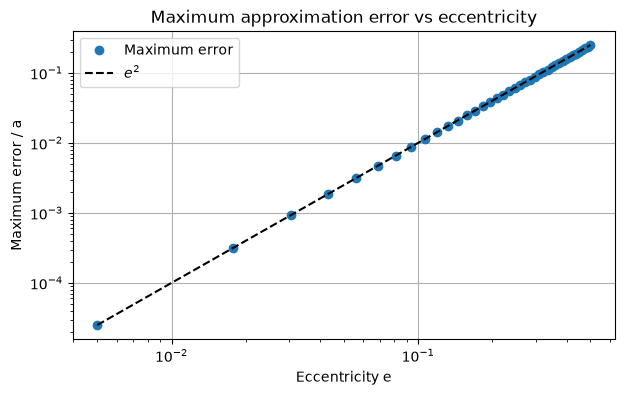

In [9]:
eccentricities = np.linspace(0.005, 0.5, 40)
max_error = []

for ecc in eccentricities:
  xe, ye = exact_orbit(a, ecc, M)
  xc, yc, _, _ = guiding_center(a, ecc, M)
  max_error.append(np.max(np.sqrt((xe - xc)**2 + (ye - yc)**2)) / a)

plt.figure(figsize=(7, 4))
plt.loglog(eccentricities, max_error, 'o', label='Maximum error')
plt.loglog(eccentricities, eccentricities**2, 'k--', label='$e^2$')
plt.title('Maximum approximation error vs eccentricity')
plt.xlabel('Eccentricity e')
plt.ylabel('Maximum error / a')
plt.legend()
plt.grid()
plt.savefig('error_scaling.png', dpi=110)
plt.show()

On a log-log scale the points follow a line parallel to $e^2$, confirming the quadratic scaling. For some Solar System bodies:

In [10]:
solar_system = {'Venus': 0.0068, 'Earth': 0.0167, 'Moon': 0.0549,
                'Mars': 0.0934, 'Mercury': 0.2056, 'Pluto': 0.2488}

for name, ecc in solar_system.items():
  xe, ye = exact_orbit(a, ecc, M)
  xc, yc, _, _ = guiding_center(a, ecc, M)
  err = np.max(np.sqrt((xe - xc)**2 + (ye - yc)**2)) / a
  print(f"{name:10s} e = {ecc:.4f}   max error = {err:.2e} a")

Venus      e = 0.0068   max error = 4.62e-05 a
Earth      e = 0.0167   max error = 2.79e-04 a
Moon       e = 0.0549   max error = 3.01e-03 a
Mars       e = 0.0934   max error = 8.72e-03 a
Mercury    e = 0.2056   max error = 4.22e-02 a
Pluto      e = 0.2488   max error = 6.17e-02 a


For the Earth the maximum error is about $3\times10^{-4}\,a$, roughly 40,000 km out of 150 million (about a tenth of the Earth-Moon distance). For Mercury or Pluto the error reaches several percent of $a$ and the approximation is much rougher.

## Summary

- The guiding center approximation reproduces both the shape of a low-eccentricity orbit and the body's position in time; for $e = 0.1$ the two trajectories are nearly indistinguishable.
- The essential step is projecting $(x', y')$ onto the rotating unit vectors before adding the guiding center position.
- The error scales as $e^2$, because the guiding center equations are exactly the first-order expansion of Keplerian motion in $e$. It works very well for Venus, the Earth or the Moon and degrades for Mercury or Pluto.
- At low eccentricity, a Keplerian ellipse is a large circle traversed uniformly plus a small elliptical epicycle traversed backwards.

## References

- Murray, C. D. & Dermott, S. F. (1999). *Solar System Dynamics*. Cambridge University Press, section 2.6.
- Planetary eccentricities: NASA Planetary Fact Sheet.